# Fisher matrix for the 5PN AAK waveform, with direct derivatives

This example computes a Fisher matrix for FEW's 5PN augmented analytic kludge waveform (`Pn5AAKWaveform`), which, unlike the flux-based models, includes orbital inclination, and checks it against the true likelihood.

SEF's stable derivative is not available for this waveform, so SEF automatically switches to the direct derivative (`DirectDerivative`): finite differences of the full waveform. The notebook:

1. Computes the single-element Fisher matrix $\Gamma$ for the inclination parameter `e0`, through the LISA response.
2. Turns it into a Gaussian approximation of the 1D likelihood, with standard deviation $\sigma = 1/\sqrt{\Gamma}$.
3. Computes the true 1D likelihood over $\pm 4\sigma$ and compares the two.

The observation time is short (`T = 0.01` years) to keep the example fast. The SNR is therefore below 20, and SEF warns that the Fisher approximation may not be reliable.

**Requirements:** `lisaanalysistools` and `fastlisaresponse`, for the LISA response and noise model (see the installation guide).

*Validated with LISAAnalysisTools-cuda12x v1.2.0 and fastlisaresponse v1.1.17.*

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import few
from few.waveform import Pn5AAKWaveform
from fastlisaresponse import ResponseWrapper
from lisatools.detector import EqualArmlengthOrbits
from lisatools.sensitivity import get_sensitivity, A1TDISens, E1TDISens

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.utils import inner_product

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Set up StableEMRIFisher

- **Waveform:** FEW's 5PN AAK model.
- **Response:** first-generation TDI on equal-arm-length orbits, returning the A and E channels. `index_lambda` and `index_beta` tell the response which waveform arguments hold the sky position (`phiS` and `qS`); the first and last `t0` seconds of the signal are set to zero.
- **Noise:** the LISA PSD of each TDI channel, from `get_sensitivity` with the matching `sens_fn` (one dictionary of `noise_kwargs` per channel).

Asking for `deriv_type='stable'` shows the automatic fallback: SEF logs a message and uses `DirectDerivative` instead.

In [2]:
T = 0.01  # observation time, years
dt = 10.0  # sampling interval, seconds

ResponseWrapper_kwargs = dict(
    Tobs=T,
    dt=dt,
    index_lambda=8,  # position of phiS in the waveform arguments
    index_beta=7,  # position of qS in the waveform arguments
    t0=10000.0,  # seconds at each end of the signal where the response is unreliable
    remove_garbage="zero",  # zero the signal within t0 of each end
    flip_hx=True,  # FEW returns h+ - i hx
    is_ecliptic_latitude=False,  # qS is a polar angle, not a latitude
    orbits=EqualArmlengthOrbits(),
    order=20,  # order of the Lagrange interpolation of the time delays
    tdi="1st generation",
    tdi_chan="AE",
)

channels = [A1TDISens, E1TDISens]

sef = StableEMRIFisher(
    waveform_class=Pn5AAKWaveform,
    waveform_class_kwargs=dict(inspiral_kwargs=dict(err=1e-13)),  # trajectory integrator tolerance
    ResponseWrapper=ResponseWrapper,
    ResponseWrapper_kwargs=ResponseWrapper_kwargs,
    noise_model=get_sensitivity,
    noise_kwargs=[{"sens_fn": channel} for channel in channels],
    channels=channels,
    deriv_type="stable",  # not available for Pn5AAKWaveform: SEF uses DirectDerivative
    use_gpu=use_gpu,
)

StableDerivative does not support the Pn5AAKWaveform waveform model. Switching to DirectDerivative.


## Compute the Fisher element for `e0`

`waveform_kwargs=dict(mich=True)` is passed through to `Pn5AAKWaveform` (its `mich` option). SEF tries `Ndelta` step sizes from its default grid and keeps the one where the diagonal Fisher element is most stable. `stability_plot=True` plots this search, and `stats_for_nerds=True` prints the chosen step size.

Waveform Generated. SNR: 14.777438938389421
The optimal source SNR is <= 20. The Fisher approximation may not be valid!
minimum relative error is greater than 1% for e0. Fisher may be unstable!  
  e0         delta = 1.404e-05   relerr = 1.3e-02   (12 steps)             
Choosing step sizes: 100%|██████████| 12/12 [00:02<00:00,  4.61deriv/s]    


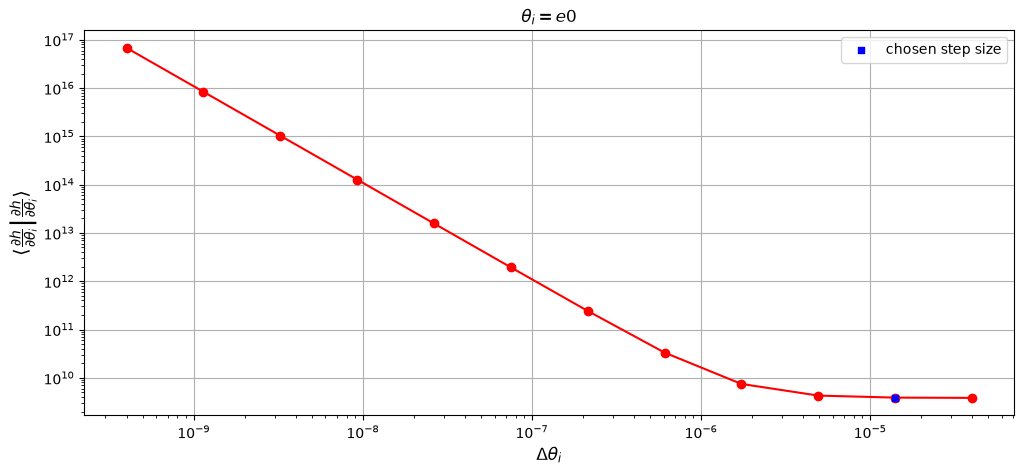

Computing Fisher   : 100%|██████████| 1/1 [00:00<00:00,  4.68deriv/s]    
Calculated Fisher is positive-definite.
Fisher estimate: sigma(e0) = 1.603e-05


In [3]:
wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=10.0,  # secondary mass, solar masses
    a=0.9,  # primary spin
    p0=9.5,  # initial semi-latus rectum
    e0=0.4,  # initial eccentricity
    xI0=0.5,  # cosine of the initial inclination
    dist=0.1,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # initial polar phase
    Phi_r0=0.0,  # initial radial phase
)

param = "e0"

Fisher = sef(
    wave_params,
    param_names=[param],
    waveform_kwargs=dict(mich=True),
    der_order=4,
    Ndelta=12,
    stability_plot=True,
    stats_for_nerds=True,
)

sigma = 1 / np.sqrt(Fisher[0, 0])
print(f"Fisher estimate: sigma({param}) = {sigma:.3e}")

## Compare with the true likelihood

The reference ("injected") waveform is the one SEF computed. If the inspiral plunges before the end of the observation, the derivatives are zero-padded at the end; `npad` is the number of padded samples (0 here), and those samples are zeroed in every waveform below so that all of them cover the same span. The first `t0` seconds of the A channel are zero, as set in the response.

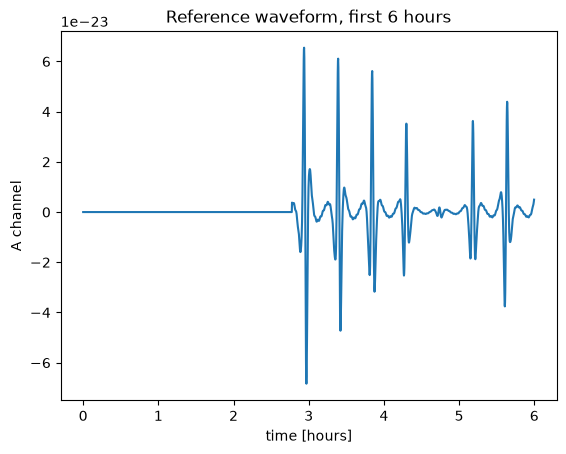

In [5]:
npad = sef.derivative.npad
N = sef.waveform.shape[-1]

reference = sef.waveform.copy()
reference[:, N - npad:] = 0.0

# plot the first 6 hours of the A channel
n_show = int(6 * 3600 / dt)
time_hours = np.arange(n_show) * dt / 3600
plt.plot(time_hours, reference[0, :n_show].get() if use_gpu else reference[0, :n_show])
plt.xlabel("time [hours]")
plt.ylabel("A channel")
plt.title("Reference waveform, first 6 hours")
plt.show()

Now vary `e0` over $\pm 4\sigma$ around its true value. At each point, generate a template waveform $h$ with the same generator SEF uses (including the response and `mich=True`) and compute the (noise-free) likelihood

$$\mathcal{L} \propto \exp\left[-\tfrac{1}{2}\left(h_{\rm ref} - h \,\middle|\, h_{\rm ref} - h\right)\right].$$

This loop generates 50 waveforms, so it is the slowest step of the notebook.

In [6]:
values = np.linspace(wave_params[param] - 4 * sigma, wave_params[param] + 4 * sigma, 50)

log_like = []
for value in tqdm(values, desc="Likelihood", file=sys.stdout):
    params = dict(sef.wave_params, **{param: value})
    template = sef.derivative.generate(*params.values(), **sef.current_waveform_kwargs)
    template[:, N - npad:] = 0.0
    residual = reference - template
    log_like.append(-0.5 * inner_product(residual, residual, sef.PSD_funcs, dt, use_gpu=use_gpu))

likelihood = np.exp(np.array(log_like) - max(log_like))
gaussian = np.exp(-0.5 * ((values - wave_params[param]) / sigma) ** 2)

Likelihood: 100%|██████████| 50/50 [00:02<00:00, 17.51it/s]


Compare the normalised true likelihood (black) with the Gaussian predicted by the Fisher matrix (red, dashed).

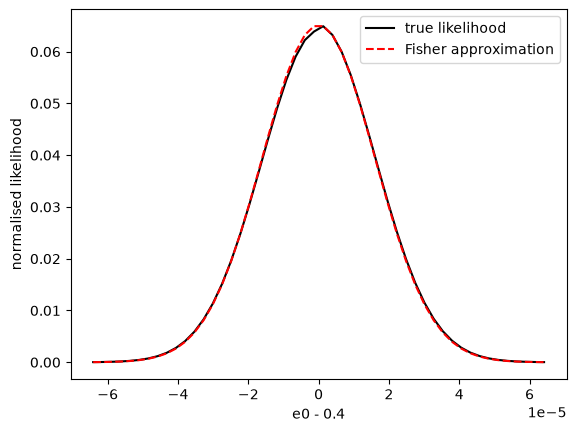

In [7]:
offset = values - wave_params[param]
plt.plot(offset, likelihood / likelihood.sum(), "k", label="true likelihood")
plt.plot(offset, gaussian / gaussian.sum(), "r--", label="Fisher approximation")
plt.xlabel(f"{param} - {wave_params[param]}")
plt.ylabel("normalised likelihood")
plt.legend()
plt.show()

## What this shows

SEF also works for waveform models without a stable derivative, through `DirectDerivative`. The Fisher matrix describes the likelihood well for `xI0` when the two curves overlap, even at this low SNR.